In [1]:

import zipfile
import pandas as pd
import io

# Читаем CSV-файл из архива
with zipfile.ZipFile("customers.zip", "r") as archive:
    with archive.open("customers.csv") as file:
        df = pd.read_csv(file)

# Выводим первые строки
print("Размер набора данных:", df.shape)
print("\nПервые 5 строк:")
display(df.head())

print("\nИнформация о столбцах:")
df.info()

print("\nКоличество пропущенных значений:")
print(df.isnull().sum())


Размер набора данных: (850, 10)

Первые 5 строк:


,Row,CustomerId,Age,Education,YearsEmployed,Income,CardDebt,OtherDebt,Defaulted,DebtIncomeRatio
0,0,1,41,2,6,19,0.124,1.073,0.0,6.3
1,1,2,47,1,26,100,4.582,8.218,0.0,12.8
2,2,3,33,2,10,57,6.111,5.802,1.0,20.9
3,3,4,29,2,4,19,0.681,0.516,0.0,6.3
4,4,5,47,1,31,253,9.308,8.908,0.0,7.2



Информация о столбцах:
<class 'pandas.DataFrame'>
RangeIndex: 850 entries, 0 to 849
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Row              850 non-null    int64  
 1   CustomerId       850 non-null    int64  
 2   Age              850 non-null    int64  
 3   Education        850 non-null    int64  
 4   YearsEmployed    850 non-null    int64  
 5   Income           850 non-null    int64  
 6   CardDebt         850 non-null    float64
 7   OtherDebt        850 non-null    float64
 8   Defaulted        700 non-null    float64
 9   DebtIncomeRatio  850 non-null    float64
dtypes: float64(4), int64(6)
memory usage: 66.5 KB

Количество пропущенных значений:
Row                  0
CustomerId           0
Age                  0
Education            0
YearsEmployed        0
Income               0
CardDebt             0
OtherDebt            0
Defaulted          150
DebtIncomeRatio      0
dtype: int64


In [2]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Выбираем признаки клиентов для кластеризации
features = [
    "Age",
    "Education",
    "YearsEmployed",
    "Income",
    "CardDebt",
    "OtherDebt",
    "DebtIncomeRatio"
]

X = df[features].copy()

# Проверяем пропущенные значения
print("Пропуски в выбранных признаках:")
print(X.isnull().sum())

# Стандартизируем признаки
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Создаем таблицу подготовленных данных
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print("\nРазмер подготовленного набора:", X_scaled.shape)
display(X_scaled_df.head())


Пропуски в выбранных признаках:
Age                0
Education          0
YearsEmployed      0
Income             0
CardDebt           0
OtherDebt          0
DebtIncomeRatio    0
dtype: int64

Размер подготовленного набора: (850, 7)


,Age,Education,YearsEmployed,Income,CardDebt,OtherDebt,DebtIncomeRatio
0,0.742915,0.312122,-0.378790,-0.718459,-0.683811,-0.590489,-0.576525
1,1.489490,-0.766349,2.573721,1.384325,1.414474,1.512962,0.391387
2,-0.252518,0.312122,0.211712,0.268032,2.134141,0.801704,1.597554
3,-0.750235,0.312122,-0.674041,-0.718459,-0.421643,-0.754467,-0.576525
4,1.489490,-0.766349,3.311849,5.356249,3.638900,1.716094,-0.442507


In [5]:

import numpy as np
from sklearn.metrics import pairwise_distances

def k_means(X, k, max_iter=100, random_state=42):
    """Кластеризация методом k-Means."""
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(random_state)

    # Случайно выбираем начальные центры
    centers = X[rng.choice(len(X), size=k, replace=False)].copy()

    for _ in range(max_iter):
        # Назначаем каждый объект ближайшему центру
        distances = pairwise_distances(X, centers)
        labels = np.argmin(distances, axis=1)

        # Пересчитываем центры как средние значения
        new_centers = centers.copy()
        for j in range(k):
            cluster_points = X[labels == j]
            if len(cluster_points) > 0:
                new_centers[j] = cluster_points.mean(axis=0)
            else:
                new_centers[j] = X[rng.integers(len(X))]

        # Останавливаемся, если центры больше не меняются
        if np.allclose(centers, new_centers):
            centers = new_centers
            break

        centers = new_centers

    # Финальное назначение кластеров и расчёт ошибки
    distances = pairwise_distances(X, centers)
    labels = np.argmin(distances, axis=1)
    error = np.sum((X - centers[labels]) ** 2)

    return labels, centers, error


def k_medoids(X, k, max_iter=100, random_state=42):
    """Кластеризация методом k-Medoids."""
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(random_state)

    # Матрица расстояний между всеми объектами
    D = pairwise_distances(X)

    # Начальные медоиды — реальные объекты набора
    medoids = rng.choice(len(X), size=k, replace=False)

    for _ in range(max_iter):
        # Назначаем объекты ближайшим медоидам
        labels = np.argmin(D[:, medoids], axis=1)
        new_medoids = medoids.copy()

        for j in range(k):
            indices = np.where(labels == j)[0]

            if len(indices) == 0:
                continue

            # Медоид — объект с минимальной суммой расстояний
            cluster_distances = D[np.ix_(indices, indices)]
            costs = cluster_distances.sum(axis=1)
            new_medoids[j] = indices[np.argmin(costs)]

        if np.array_equal(medoids, new_medoids):
            break

        medoids = new_medoids

    # Финальное назначение объектов
    labels = np.argmin(D[:, medoids], axis=1)

    # SSE: сумма квадратов расстояний до медоидов
    error = np.sum(D[np.arange(len(X)), medoids[labels]] ** 2)

    return labels, X[medoids], error


print("Функции k-Means и k-Medoids успешно созданы.")


k = 3

labels_kmeans, centers_kmeans, error_kmeans = k_means(
    X_scaled, k
)

labels_kmedoids, centers_kmedoids, error_kmedoids = k_medoids(
    X_scaled, k
)

print(f"k-Means, k={k}")
print("Ошибка SSE:", round(error_kmeans, 3))
print("Размеры кластеров:", np.bincount(labels_kmeans))

print(f"\nk-Medoids, k={k}")
print("Ошибка SSE:", round(error_kmedoids, 3))
print("Размеры кластеров:", np.bincount(labels_kmedoids))

# Покажем координаты первых 10 объектов и назначенные кластеры
results = df[["CustomerId"] + features].copy()
results["Cluster_kMeans"] = labels_kmeans
results["Cluster_kMedoids"] = labels_kmedoids

display(results.head(10))



Функции k-Means и k-Medoids успешно созданы.
k-Means, k=3
Ошибка SSE: 3844.922
Размеры кластеров: [108 570 172]

k-Medoids, k=3
Ошибка SSE: 4211.69
Размеры кластеров: [ 82 631 137]


,CustomerId,Age,Education,YearsEmployed,Income,CardDebt,OtherDebt,DebtIncomeRatio,Cluster_kMeans,Cluster_kMedoids
0,1,41,2,6,19,0.124,1.073,6.3,1,1
1,2,47,1,26,100,4.582,8.218,12.8,0,0
2,3,33,2,10,57,6.111,5.802,20.9,2,2
3,4,29,2,4,19,0.681,0.516,6.3,1,1
4,5,47,1,31,253,9.308,8.908,7.2,0,0
5,6,40,1,23,81,0.998,7.831,10.9,0,0
6,7,38,2,4,56,0.442,0.454,1.6,1,1
7,8,42,3,0,64,0.279,3.945,6.6,1,1
8,9,26,1,5,18,0.575,2.215,15.5,1,1
9,10,47,3,23,115,0.653,3.947,4.0,0,0


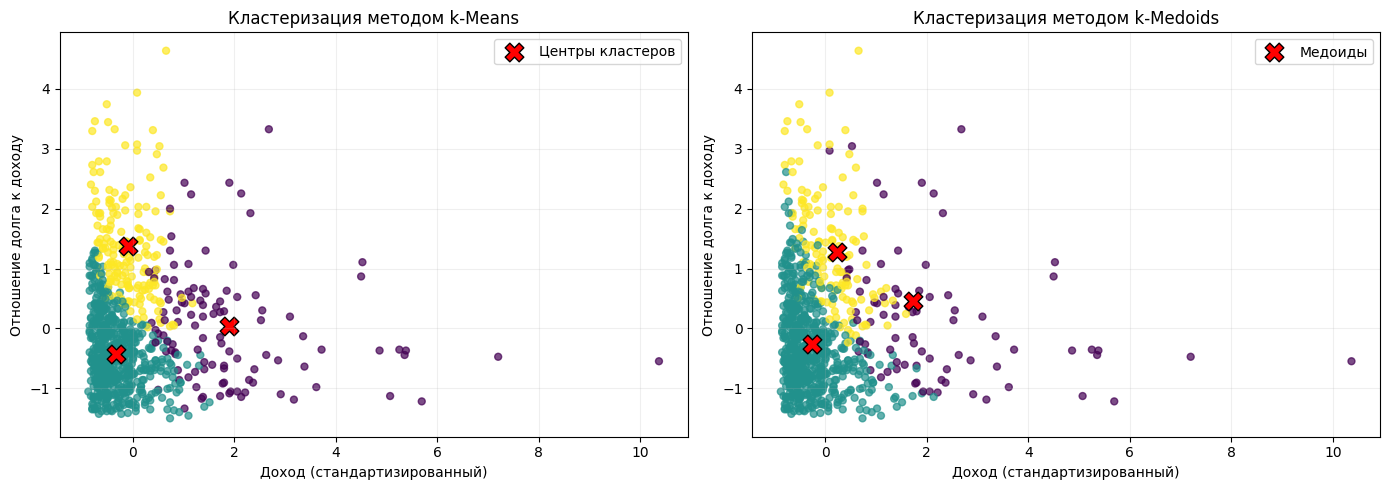

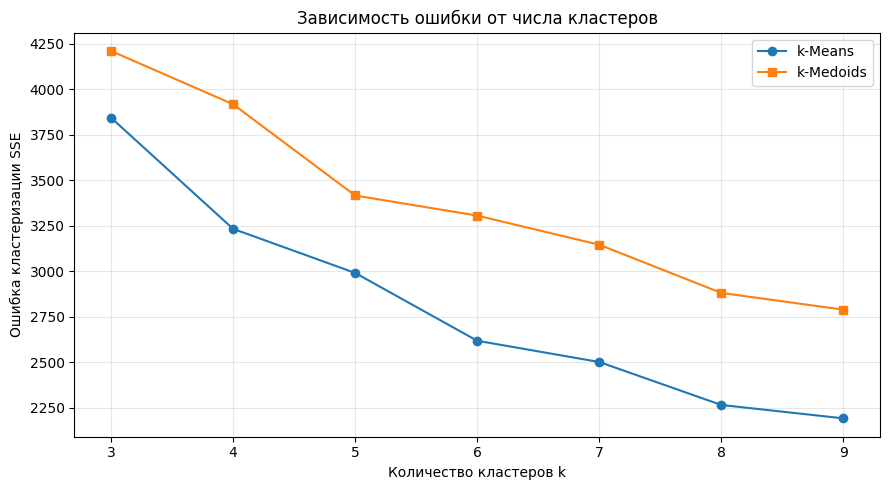

,k,SSE_kMeans,SSE_kMedoids
0,3,3844.922,4211.690
1,4,3233.915,3918.675
2,5,2991.561,3417.155
3,6,2618.704,3306.608
4,7,2501.955,3146.478
5,8,2265.805,2881.703
6,9,2192.220,2789.506


In [7]:

import matplotlib.pyplot as plt

# Два признака для отображения на плоскости
x_feature = "Income"
y_feature = "DebtIncomeRatio"

x_idx = features.index(x_feature)
y_idx = features.index(y_feature)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График k-Means
axes[0].scatter(
    X_scaled[:, x_idx],
    X_scaled[:, y_idx],
    c=labels_kmeans,
    cmap="viridis",
    s=25,
    alpha=0.7
)
axes[0].scatter(
    centers_kmeans[:, x_idx],
    centers_kmeans[:, y_idx],
    marker="X",
    s=180,
    c="red",
    edgecolors="black",
    label="Центры кластеров"
)
axes[0].set_title("Кластеризация методом k-Means")
axes[0].set_xlabel("Доход (стандартизированный)")
axes[0].set_ylabel("Отношение долга к доходу")
axes[0].legend()
axes[0].grid(alpha=0.2)

# График k-Medoids
axes[1].scatter(
    X_scaled[:, x_idx],
    X_scaled[:, y_idx],
    c=labels_kmedoids,
    cmap="viridis",
    s=25,
    alpha=0.7
)
axes[1].scatter(
    centers_kmedoids[:, x_idx],
    centers_kmedoids[:, y_idx],
    marker="X",
    s=180,
    c="red",
    edgecolors="black",
    label="Медоиды"
)
axes[1].set_title("Кластеризация методом k-Medoids")
axes[1].set_xlabel("Доход (стандартизированный)")
axes[1].set_ylabel("Отношение долга к доходу")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


k_values = range(3, 10)

errors_kmeans = []
errors_kmedoids = []

for k in k_values:
    _, _, error1 = k_means(X_scaled, k, random_state=42)
    _, _, error2 = k_medoids(X_scaled, k, random_state=42)

    errors_kmeans.append(error1)
    errors_kmedoids.append(error2)

plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values), errors_kmeans,
    marker="o", label="k-Means"
)
plt.plot(
    list(k_values), errors_kmedoids,
    marker="s", label="k-Medoids"
)

plt.xlabel("Количество кластеров k")
plt.ylabel("Ошибка кластеризации SSE")
plt.title("Зависимость ошибки от числа кластеров")
plt.xticks(list(k_values))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Таблица ошибок
error_table = pd.DataFrame({
    "k": list(k_values),
    "SSE_kMeans": errors_kmeans,
    "SSE_kMedoids": errors_kmedoids
})

display(error_table.round(3))

